In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [17]:
def rk4(fun, tempos, y0):
    y = [np.array(y0, dtype=float)]
    dt = tempos[1] - tempos[0]
    for t in tempos[:-1]:
        k1 = fun(t, y[-1])
        k2 = fun(t + dt/2, y[-1] + dt*k1/2)
        k3 = fun(t + dt/2, y[-1] + dt*k2/2)
        k4 = fun(t + dt, y[-1] + dt*k3)
        y.append(y[-1] + dt/6*(k1 + 2*k2 + 2*k3 + k4))
    return np.array(y)

In [18]:
def aceleracoes(y, g=9.8, l=1.0):
    theta1, theta2, w1, w2 = y
    delta = theta1 - theta2
    den = 16 - 9*np.cos(delta)**2
    a1 = -3*(2*w2**2*np.sin(delta) + 3*np.cos(delta)*w1**2*np.sin(delta)
             + 6*(g/l)*np.sin(theta1) - 3*np.cos(delta)*(g/l)*np.sin(theta2))/den
    a2 = 3*(8*w1**2*np.sin(delta) + 3*np.cos(delta)*w2**2*np.sin(delta)
            - 8*(g/l)*np.sin(theta2) + 9*np.cos(delta)*(g/l)*np.sin(theta1))/den
    return a1, a2

def derivadas(y, g=9.8, l=1.0):
    a1, a2 = aceleracoes(y, g=g, l=l)
    return np.array([y[2], y[3], a1, a2])

def energia(y, m=1.0, g=9.8, l=1.0):
    th1, th2, w1, w2 = y
    T = m*l**2/6*(4*w1**2 + w2**2 + 3*w1*w2*np.cos(th1-th2))
    U = -0.5*m*g*l*(3*np.cos(th1) + np.cos(th2))
    return T + U

In [ ]:
tempos = np.arange(0, 300, 0.005)

velocidades = [0.0, 0.25, 0.50, 0.75, 1.00]
cores = ["tab:blue", "tab:red", "tab:green", "tab:orange", "tab:purple"]

condicoes_energia = {}
for w in velocidades:
    y0 = np.array([np.pi/2, np.pi/2, w, w])
    energia_inicial = energia(y0)
    nome = f"E₀ = {energia_inicial:.3f} J  (ω₀ = {w:.2f})"
    condicoes_energia[nome] = y0

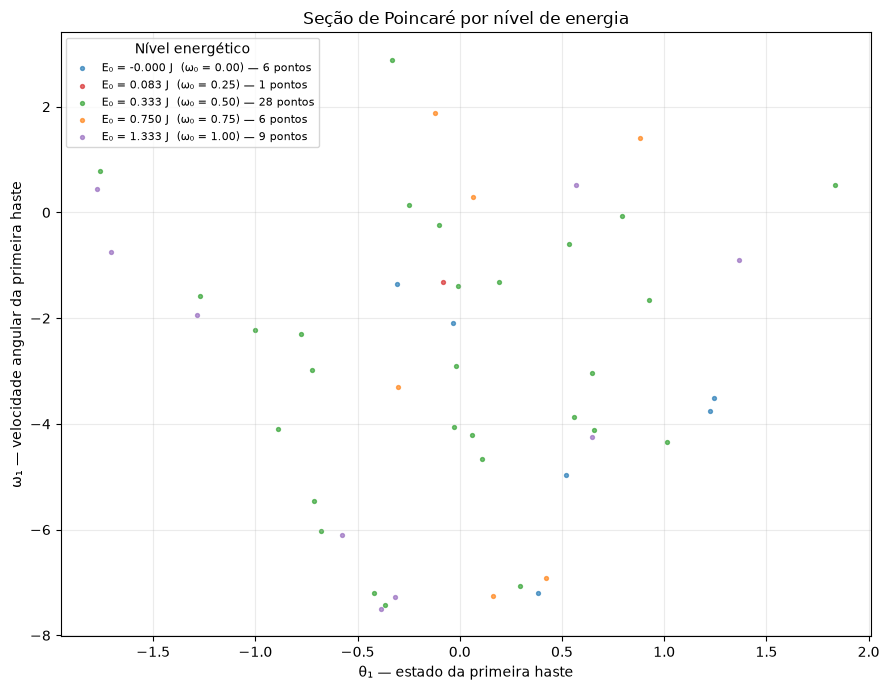

In [22]:
def secao_por_nivel_de_energia(tempos, y0, g=9.8, l=1.0):
    fun = lambda t, y: derivadas(y, g=g, l=l)
    estados = rk4(fun, tempos, y0)
    pontos = []

    for i in range(len(estados)-1):
        th2_atual = estados[i, 1]
        th2_seguinte = estados[i+1, 1]

        if th2_atual * th2_seguinte < 0 and estados[i+1, 3] > 0:
            alpha = -th2_atual/(th2_seguinte-th2_atual)
            th1_p = estados[i, 0] + alpha*(estados[i+1, 0]-estados[i, 0])
            w1_p = estados[i, 2] + alpha*(estados[i+1, 2]-estados[i, 2])
            pontos.append([th1_p, w1_p])

    return np.array(pontos)


plt.figure(figsize=(9, 7))

for (nome, y0), cor in zip(condicoes_energia.items(), cores):
    pontos = secao_por_nivel_de_energia(tempos, y0)

    if len(pontos):
        plt.scatter(pontos[:, 0], pontos[:, 1], s=8, alpha=0.65,
                    color=cor, label=f"{nome} — {len(pontos)} pontos")

plt.title("Seção de Poincaré por nível de energia", fontsize=12)
plt.xlabel("θ₁ — estado da primeira haste", fontsize=10)
plt.ylabel("ω₁ — velocidade angular da primeira haste", fontsize=10)
plt.grid(alpha=0.25)
plt.legend(fontsize=8, title="Nível energético")
plt.tight_layout()
plt.savefig("secao_poincare_por_energia.png", dpi=150, bbox_inches="tight")
plt.show()